In [ ]:
import sys
from pathlib import Path
import math
import matplotlib.pyplot as plt
from PIL import Image

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.load_metadata import load_metadata

metadata = load_metadata()
metadata.head()

,record_index,char,unicode,source_file,image_path
0,0,ア,0x30a2,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
1,1,ア,0x30a2,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
2,2,ア,0x30a2,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
3,3,ア,0x30a2,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...
4,4,ア,0x30a2,ETL1C_07,/Users/nailito/Desktop/Data/katakana-recogniti...


Katakana expected to be present : 46/46
Additional : ヰ, ヱ


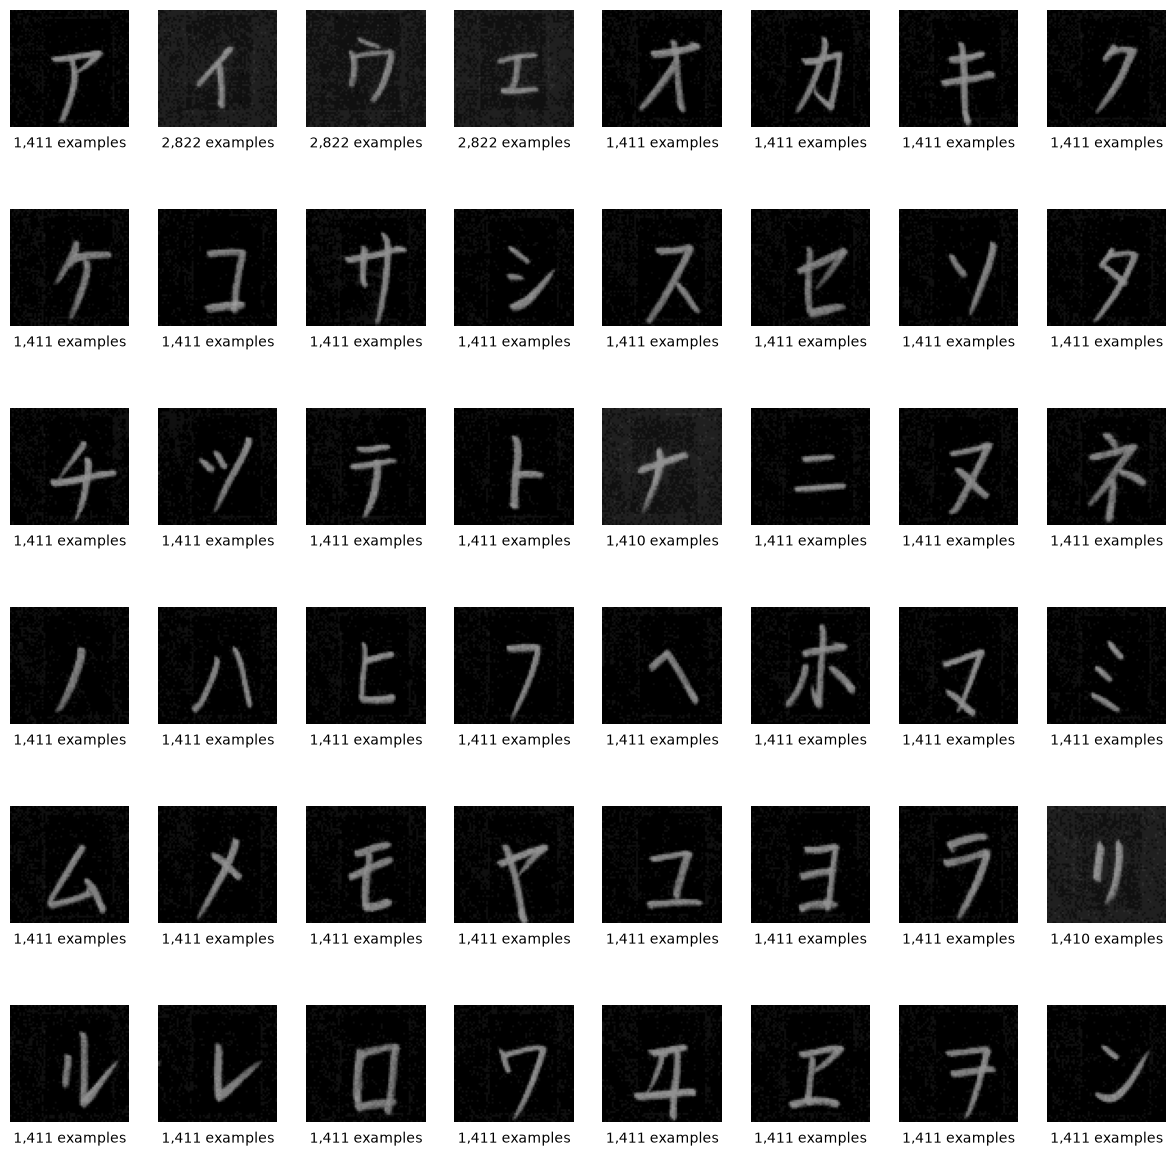

In [9]:
expected = set(
    "アイウエオ"
    "カキクケコ"
    "サシスセソ"
    "タチツテト"
    "ナニヌネノ"
    "ハヒフヘホ"
    "マミムメモ"
    "ヤユヨ"
    "ラリルレロ"
    "ワヲン"
)

present = set(metadata["char"].dropna())
missing = expected - present
extra = present - expected

print(f"Katakana expected to be present : {len(expected & present)}/46")
print("Additional :", ", ".join(sorted(extra)) or "aucun")

if missing:
    raise ValueError(
        f"Missing Katakana : {', '.join(sorted(missing))}"
    )

font = globals().get("jp_font")

groups = list(metadata.groupby("char", sort=False))
ncols = 8
nrows = math.ceil(len(groups) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(12, nrows * 2),
    squeeze=False
)

for ax in axes.flat:
    ax.set_axis_off()

for ax, (character, group) in zip(axes.flat, groups):
    row = group.sample(n=1, random_state=23).iloc[0]

    with Image.open(row["image_path"]) as image:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)

    if font is not None:
        ax.set_title(character, fontproperties=font)

    ax.text(
        0.5, -0.08,
        f"{len(group):,} examples",
        transform=ax.transAxes,
        ha="center",
        va="top"
    )

plt.tight_layout(h_pad=3)
plt.show()